# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

rng = np.random.default_rng(42)

# Find the dataset
paths = [
    Path("data/cars.csv"),
    Path("../data/cars.csv"),
    Path("cars.csv")
]

file_path = next((p for p in paths if p.exists()), None)

if file_path is None:
    raise FileNotFoundError("Please put cars.csv in the data folder.")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [6]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()

# Check rows and columns
print("Shape:", df.shape)

# Check column names and types
print("\nColumns:")
print(df.dtypes)

# Find missing values
print("\nMissing values:")
print(df.isna().sum())

# Find duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Summary statistics
print("\nSummary:")
display(df.describe(include="all"))

# Most common prices
print("\nMost common MSRP values:")
print(df["MSRP"].value_counts().head(10))

# Highest prices
print("\nMost expensive cars:")
display(
    df.nlargest(10, "MSRP")[
        ["Make", "Model", "Year", "MSRP"]
    ]
)

# Highest highway MPG
print("\nHighest highway MPG:")
display(
    df.nlargest(10, "highway MPG")[
        ["Make", "Model", "Engine Fuel Type", "highway MPG"]
    ]
)

# Missing values by car make
print("\nMissing horsepower by make:")
print(
    df.groupby("Make")["Engine HP"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
    .head(10)
)


Shape: (11914, 15)

Columns:
Make                  object
Model                 object
Year                   int64
Engine Fuel Type      object
Engine HP            float64
Engine Cylinders     float64
Transmission Type     object
Driven_Wheels         object
Number of Doors      float64
Vehicle Size          object
Vehicle Style         object
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

Missing values:
Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64

Duplicate rows:
720

Summary:


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
count,11914,11914,11914.000000,11911,11845.00000,11884.000000,11914,11914,11908.000000,11914,11914,11914.000000,11914.000000,11914.000000,1.191400e+04
unique,48,915,NaN,10,NaN,NaN,5,4,NaN,3,16,NaN,NaN,NaN,NaN
top,Chevrolet,Silverado 1500,NaN,regular unleaded,NaN,NaN,AUTOMATIC,front wheel drive,NaN,Compact,Sedan,NaN,NaN,NaN,NaN
freq,1123,156,NaN,7172,NaN,NaN,8266,4787,NaN,4764,3048,NaN,NaN,NaN,NaN
mean,NaN,NaN,2010.384338,NaN,249.38607,5.628829,NaN,NaN,3.436093,NaN,NaN,26.637485,19.733255,1554.911197,4.059474e+04
std,NaN,NaN,7.579740,NaN,109.19187,1.780559,NaN,NaN,0.881315,NaN,NaN,8.863001,8.987798,1441.855347,6.010910e+04
min,NaN,NaN,1990.000000,NaN,55.00000,0.000000,NaN,NaN,2.000000,NaN,NaN,12.000000,7.000000,2.000000,2.000000e+03
25%,NaN,NaN,2007.000000,NaN,170.00000,4.000000,NaN,NaN,2.000000,NaN,NaN,22.000000,16.000000,549.000000,2.100000e+04
50%,NaN,NaN,2015.000000,NaN,227.00000,6.000000,NaN,NaN,4.000000,NaN,NaN,26.000000,18.000000,1385.000000,2.999500e+04
75%,NaN,NaN,2016.000000,NaN,300.00000,6.000000,NaN,NaN,4.000000,NaN,NaN,30.000000,22.000000,2009.000000,4.223125e+04



Most common MSRP values:
MSRP
2000     1036
29995      19
25995      19
27995      16
20995      16
30995      15
23995      15
21995      14
24995      14
26195      13
Name: count, dtype: int64

Most expensive cars:


,Make,Model,Year,MSRP
11362,Bugatti,Veyron 16.4,2008,2065902
11364,Bugatti,Veyron 16.4,2009,1705769
8486,Lamborghini,Reventon,2008,1500000
11363,Bugatti,Veyron 16.4,2008,1500000
6351,Maybach,Landaulet,2012,1382750
6350,Maybach,Landaulet,2011,1380000
4024,Ferrari,Enzo,2003,643330
1622,Lamborghini,Aventador,2014,548800
1626,Lamborghini,Aventador,2015,548800
1629,Lamborghini,Aventador,2016,535500



Highest highway MPG:


,Make,Model,Engine Fuel Type,highway MPG
1119,Audi,A6,premium unleaded (recommended),354
5790,BMW,i3,electric,111
5791,BMW,i3,electric,111
5792,BMW,i3,electric,111
1983,Chevrolet,Bolt EV,electric,110
1984,Chevrolet,Bolt EV,electric,110
9867,Chevrolet,Spark EV,electric,109
9868,Chevrolet,Spark EV,electric,109
9869,Chevrolet,Spark EV,electric,109
9870,Chevrolet,Spark EV,electric,109



Missing horsepower by make:
Make
Tesla         18
Ford          13
Nissan        10
Lincoln        8
Chevrolet      6
Kia            5
FIAT           3
Honda          2
Toyota         2
Mitsubishi     1
Name: Engine HP, dtype: int64


**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |
| 4 | | | | | |
| 5 | | | | | |

In [9]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.

# Start with a copy
clean = df.copy()

# Make column names easier to use
clean.columns = (
    clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Remove exact duplicate rows
duplicates = clean.duplicated().sum()
clean = clean.drop_duplicates().copy()

# Standardize text
clean["transmission_type"] = (
    clean["transmission_type"].str.strip().str.upper()
)

clean["vehicle_size"] = (
    clean["vehicle_size"].str.strip().str.title()
)

clean["engine_fuel_type"] = (
    clean["engine_fuel_type"].str.strip().str.lower()
)

# Fix invalid prices
clean.loc[clean["msrp"] <= 0, "msrp"] = np.nan

# Check whether $2,000 is a placeholder
placeholder_count = (clean["msrp"] == 2000).sum()
print("MSRP exactly $2,000:", placeholder_count)

# Apply only if the data suggests it is a placeholder
clean["msrp_2000_flag"] = clean["msrp"] == 2000

# Set to False if $2,000 is a legitimate price
treat_2000_as_missing = True

if treat_2000_as_missing:
    clean.loc[clean["msrp_2000_flag"], "msrp"] = np.nan

# Fix impossible MPG values
clean.loc[clean["highway_mpg"] <= 0, "highway_mpg"] = np.nan
clean.loc[clean["city_mpg"] <= 0, "city_mpg"] = np.nan

# Flag MPG figures that may not be comparable
# Electric vehicles may report MPGe instead of MPG
clean["mpg_not_comparable"] = (
    clean["engine_fuel_type"].str.contains(
        "electric", na=False
    )
    | (clean["highway_mpg"] > 80)
    | (clean["city_mpg"] > 80)
)

clean["highway_mpg_trusted"] = (
    clean["highway_mpg"].where(~clean["mpg_not_comparable"])
)

# Fix impossible horsepower
clean.loc[clean["engine_hp"] <= 0, "engine_hp"] = np.nan

# Flag extremely expensive cars for inspection
clean["expensive_car_flag"] = clean["msrp"] > 500000

# Check the results
print("Original rows:", len(df))
print("Duplicate rows removed:", duplicates)
print("Cleaned rows:", len(clean))

print("\nMissing values after cleaning:")
print(clean.isna().sum())

print("\nUnusual MPG rows flagged:")
print(clean["mpg_not_comparable"].sum())

print("\nVery expensive cars flagged:")
print(clean["expensive_car_flag"].sum())

display(clean.head())


MSRP exactly $2,000: 747
Original rows: 11914
Duplicate rows removed: 720
Cleaned rows: 11194

Missing values after cleaning:
make                     0
model                    0
year                     0
engine_fuel_type         3
engine_hp               69
engine_cylinders        30
transmission_type        0
driven_wheels            0
number_of_doors          6
vehicle_size             0
vehicle_style            0
highway_mpg              0
city_mpg                 0
popularity               0
msrp                   747
msrp_2000_flag           0
mpg_not_comparable       0
highway_mpg_trusted     67
expensive_car_flag       0
dtype: int64

Unusual MPG rows flagged:
67

Very expensive cars flagged:
11


,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp,msrp_2000_flag,mpg_not_comparable,highway_mpg_trusted,expensive_car_flag
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26.0,19.0,3916,46135.0,False,False,26.0,False
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28.0,19.0,3916,40650.0,False,False,28.0,False
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28.0,20.0,3916,36350.0,False,False,28.0,False
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28.0,18.0,3916,29450.0,False,False,28.0,False
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28.0,18.0,3916,34500.0,False,False,28.0,False


In [10]:
# Checkpoint: run this before moving on.

print("Cleaned dataset shape:", clean.shape)

print("\nColumns with missing values:")
print(
    clean.isna().sum()[
        clean.isna().sum() > 0
    ]
)

print("\nDuplicate rows remaining:")
print(clean.duplicated().sum())


Cleaned dataset shape: (11194, 19)

Columns with missing values:
engine_fuel_type         3
engine_hp               69
engine_cylinders        30
number_of_doors          6
msrp                   747
highway_mpg_trusted     67
dtype: int64

Duplicate rows remaining:
0


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean MSRP: $ 44788.67
Median MSRP: $ 31870.0


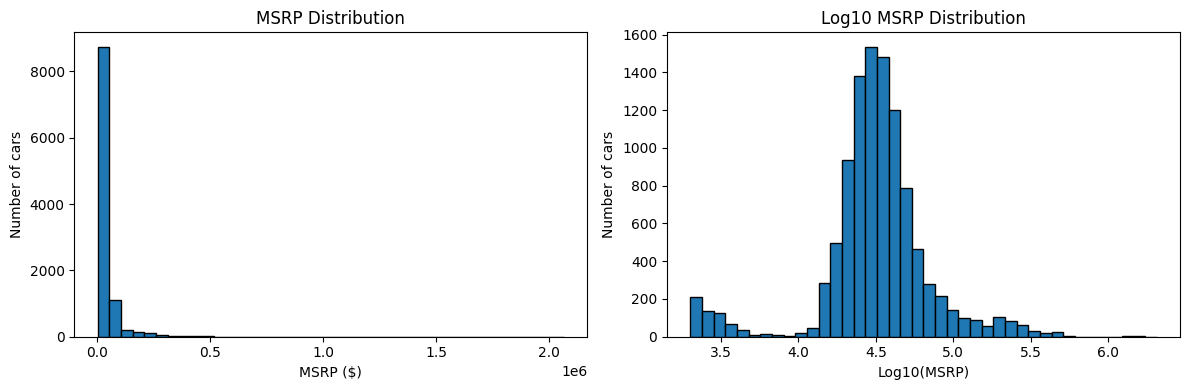

Cars costing more than the mean: 24.45 %


In [11]:
# Use valid MSRP values
prices = clean["msrp"].dropna()
prices = prices[prices > 0]

# a) Mean and median
mean_price = prices.mean()
median_price = prices.median()

print("Mean MSRP: $", round(mean_price, 2))
print("Median MSRP: $", round(median_price, 2))

# b) Plot two histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(prices, bins=40, edgecolor="black")
axes[0].set_title("MSRP Distribution")
axes[0].set_xlabel("MSRP ($)")
axes[0].set_ylabel("Number of cars")

axes[1].hist(np.log10(prices), bins=40, edgecolor="black")
axes[1].set_title("Log10 MSRP Distribution")
axes[1].set_xlabel("Log10(MSRP)")
axes[1].set_ylabel("Number of cars")

plt.tight_layout()
plt.show()

# c) Percentage above mean
percent_above_mean = (prices > mean_price).mean() * 100

print(
    "Cars costing more than the mean:",
    round(percent_above_mean, 2), "%"
)


**Answer:**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [12]:

# Select 2017 cars
cars_2017 = clean[clean["year"] == 2017].copy()

# a) Average and standard deviation by vehicle size
mpg_stats = (
    cars_2017.groupby("vehicle_size")["highway_mpg_trusted"]
    .agg(["mean", "std", "count"])
)

display(mpg_stats.round(2))

# b) Calculate z-scores
compact_mean = mpg_stats.loc["Compact", "mean"]
compact_std = mpg_stats.loc["Compact", "std"]

large_mean = mpg_stats.loc["Large", "mean"]
large_std = mpg_stats.loc["Large", "std"]

# Given values from the assignment
civic_mpg = 42
volvo_mpg = 34

civic_z = (civic_mpg - compact_mean) / compact_std
volvo_z = (volvo_mpg - large_mean) / large_std

print("Honda Civic z-score:", round(civic_z, 3))
print("Volvo S90 z-score:", round(volvo_z, 3))

# c) Compare the two vehicles
if civic_z > volvo_z:
    print("Honda Civic is more impressive for its size class.")
elif volvo_z > civic_z:
    print("Volvo S90 is more impressive for its size class.")
else:
    print("Both cars perform equally well relative to their classes.")


,mean,std,count
vehicle_size,,,
Compact,30.88,6.05,509
Large,22.99,3.49,468
Midsize,29.41,5.45,638


Honda Civic z-score: 1.839
Volvo S90 z-score: 3.153
Volvo S90 is more impressive for its size class.


**Answer:**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

2017 cars: 1624
Median MSRP: 36737.5
95% confidence interval:
35940.0 to 37682.56


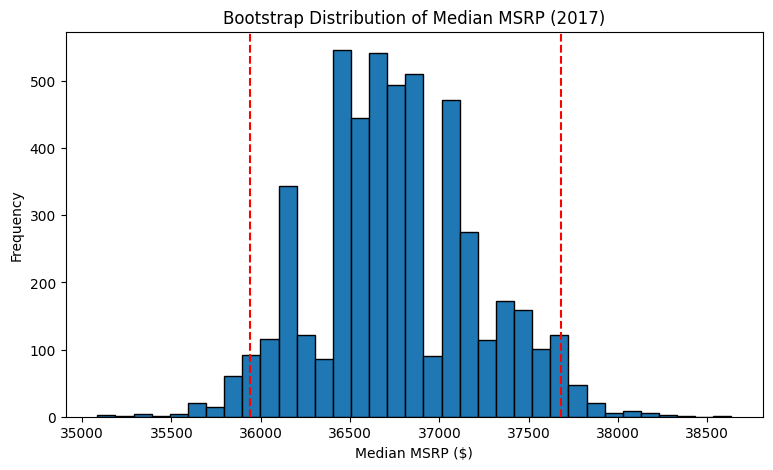

In [13]:

def bootstrap_median(values, n_boot=5000):
    """Return bootstrap median values."""

    values = np.array(pd.Series(values).dropna())

    if len(values) == 0:
        raise ValueError("No valid values for bootstrap.")

    medians = []

    for i in range(n_boot):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        medians.append(np.median(sample))

    return np.array(medians)


# a) 2017 prices
prices_2017 = clean.loc[
    clean["year"] == 2017, "msrp"
].dropna()

print("2017 cars:", len(prices_2017))
print("Median MSRP:", prices_2017.median())

# b) Bootstrap 5000 times
boot_results = bootstrap_median(prices_2017)

lower = np.percentile(boot_results, 2.5)
upper = np.percentile(boot_results, 97.5)

print("95% confidence interval:")
print(round(lower, 2), "to", round(upper, 2))

# Plot bootstrap medians
plt.figure(figsize=(9, 5))

plt.hist(
    boot_results,
    bins=35,
    edgecolor="black"
)

plt.axvline(lower, color="red", linestyle="--")
plt.axvline(upper, color="red", linestyle="--")

plt.title("Bootstrap Distribution of Median MSRP (2017)")
plt.xlabel("Median MSRP ($)")
plt.ylabel("Frequency")

plt.show()


**Answer:**

Selected make: Subaru
Number of cars: 46
Median price: 25820.0
Smaller sample 95% interval:
24045.0 to 28840.0
Overall interval width: 1742.56
Small-make interval width: 4795.0


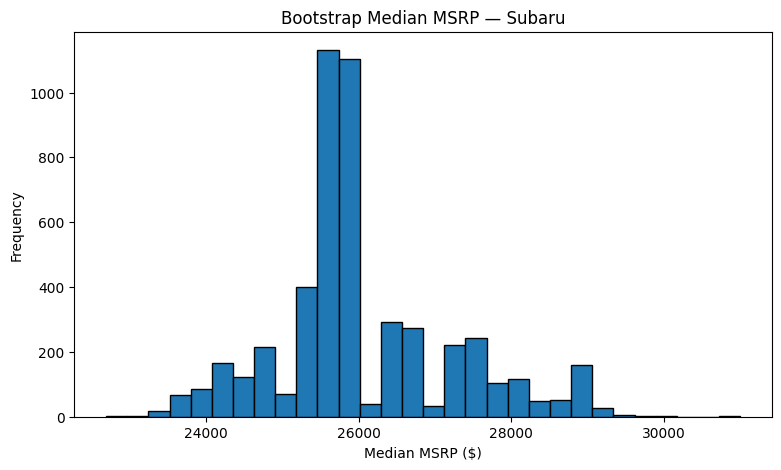

In [14]:

# Count 2017 cars by make with valid prices
valid_2017 = clean[
    (clean["year"] == 2017)
    & (clean["msrp"].notna())
]

make_counts = valid_2017["make"].value_counts()

# Choose a make with 5 to 49 cars
small_makes = make_counts[
    (make_counts >= 5) & (make_counts < 50)
]

if small_makes.empty:
    raise ValueError("No make found with 5 to 49 valid prices.")

selected_make = small_makes.index[0]

small_prices = valid_2017.loc[
    valid_2017["make"] == selected_make,
    "msrp"
]

print("Selected make:", selected_make)
print("Number of cars:", len(small_prices))
print("Median price:", small_prices.median())

# Bootstrap smaller sample
small_boot = bootstrap_median(small_prices)

small_lower = np.percentile(small_boot, 2.5)
small_upper = np.percentile(small_boot, 97.5)

print("Smaller sample 95% interval:")
print(round(small_lower, 2), "to", round(small_upper, 2))

# Compare interval widths
overall_width = upper - lower
small_width = small_upper - small_lower

print("Overall interval width:", round(overall_width, 2))
print("Small-make interval width:", round(small_width, 2))

# Plot
plt.figure(figsize=(9, 5))

plt.hist(
    small_boot,
    bins=30,
    edgecolor="black"
)

plt.title(f"Bootstrap Median MSRP — {selected_make}")
plt.xlabel("Median MSRP ($)")
plt.ylabel("Frequency")

plt.show()


---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

Number of cars: 509
Mean highway MPG: 30.88015717092338
Standard deviation: 6.045381133238401


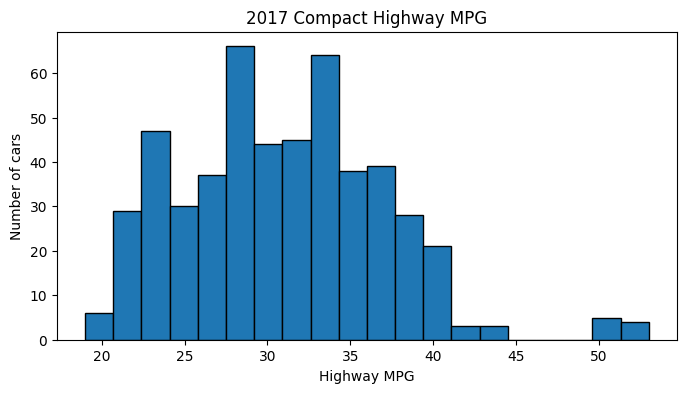

t-statistic: 3.2846979278764468
p-value: 0.0005456796119875342
Reject H0: evidence that mean MPG exceeds 30.


In [15]:

# Select 2017 compact cars
compact_2017 = clean[
    (clean["year"] == 2017)
    & (clean["vehicle_size"] == "Compact")
].copy()

# Only use trusted MPG
compact_mpg = compact_2017[
    "highway_mpg_trusted"
].dropna()

# b) Sample information
print("Number of cars:", len(compact_mpg))
print("Mean highway MPG:", compact_mpg.mean())
print("Standard deviation:", compact_mpg.std())

# Plot distribution
plt.figure(figsize=(8, 4))

plt.hist(
    compact_mpg,
    bins=20,
    edgecolor="black"
)

plt.title("2017 Compact Highway MPG")
plt.xlabel("Highway MPG")
plt.ylabel("Number of cars")

plt.show()

# c) One-sample t-test
result = stats.ttest_1samp(
    compact_mpg,
    popmean=30,
    alternative="greater"
)

print("t-statistic:", result.statistic)
print("p-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Reject H0: evidence that mean MPG exceeds 30.")
else:
    print("Do not reject H0: insufficient evidence that mean MPG exceeds 30.")


In [16]:

# Count rows per make and model
model_counts = (
    compact_2017.dropna(subset=["highway_mpg_trusted"])
    .groupby(["make", "model"])
    .size()
    .sort_values(ascending=False)
)

print("Rows per make and model:")
display(model_counts.head(20))

# Average each make-model combination first
model_means = (
    compact_2017.groupby(["make", "model"])[
        "highway_mpg_trusted"
    ]
    .mean()
    .dropna()
)

print("Number of models:", len(model_means))
print("Mean of model averages:", model_means.mean())

# Rerun t-test
model_test = stats.ttest_1samp(
    model_means,
    popmean=30,
    alternative="greater"
)

print("Model-level t-statistic:", model_test.statistic)
print("Model-level p-value:", model_test.pvalue)

print("\nOriginal row-level p-value:", result.pvalue)
print("Model-level p-value:", model_test.pvalue)


Rows per make and model:


make        model             
Toyota      Tacoma                27
Chevrolet   Corvette              24
Nissan      Frontier              22
            370Z                  17
Porsche     911                   14
Honda       Civic                 13
Audi        A3                    12
Volkswagen  Golf GTI              10
Nissan      Juke                  10
Chevrolet   Sonic                 10
Buick       Encore                10
Ford        Transit Connect        9
GMC         Terrain                9
Toyota      Corolla                9
Kia         Forte                  8
Hyundai     Tucson                 8
Lincoln     MKC                    8
Honda       HR-V                   8
Mitsubishi  Outlander Sport        8
Land Rover  Range Rover Evoque     8
dtype: int64

Number of models: 85
Mean of model averages: 31.68526472886335
Model-level t-statistic: 2.5773313510555917
Model-level p-value: 0.005851341042610616

Original row-level p-value: 0.0005456796119875342
Model-level p-value: 0.005851341042610616


**Answer:**

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

Overall median MSRP:


,count,median,mean
transmission_type,,,
AUTOMATIC,7635,33620.0,43349.61
MANUAL,2184,21875.0,33680.27



Year comparison:


,min,median,mean,max
transmission_type,,,,
AUTOMATIC,1990,2015.0,2011.84,2017
MANUAL,1990,2008.0,2006.48,2017


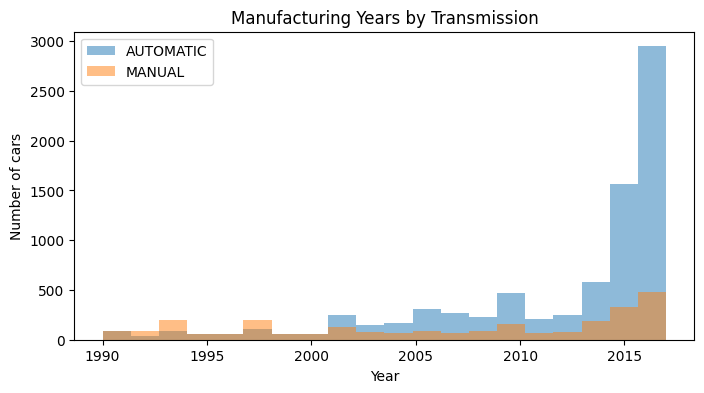


2015–2017 median prices:


,count,median
transmission_type,,
AUTOMATIC,4511,37065.0
MANUAL,813,26905.0



Median MSRP by vehicle size:


transmission_type,AUTOMATIC,MANUAL
vehicle_size,,
Compact,25995.0,25860.0
Large,44400.0,38395.0
Midsize,37980.0,26920.0



Compact automatic cars: 1119
Compact manual cars: 589
Automatic median: 25995.0
Manual median: 25860.0
Mann-Whitney U: 317261.0
p-value: 0.20483161191397048
No statistically significant difference detected.


In [17]:

# Only automatic and manual transmissions
transmission_cars = clean[
    clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])
].copy()

# a) Compare median prices
print("Overall median MSRP:")

display(
    transmission_cars.groupby("transmission_type")["msrp"]
    .agg(["count", "median", "mean"])
    .round(2)
)

# b) Compare manufacturing years
print("\nYear comparison:")

display(
    transmission_cars.groupby("transmission_type")["year"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)

# Plot year distribution
plt.figure(figsize=(8, 4))

for transmission in ["AUTOMATIC", "MANUAL"]:
    years = transmission_cars.loc[
        transmission_cars["transmission_type"] == transmission,
        "year"
    ].dropna()

    plt.hist(
        years,
        bins=20,
        alpha=0.5,
        label=transmission
    )

plt.title("Manufacturing Years by Transmission")
plt.xlabel("Year")
plt.ylabel("Number of cars")
plt.legend()
plt.show()


# c) Compare only 2015–2017 cars
recent = transmission_cars[
    transmission_cars["year"].between(2015, 2017)
].copy()

print("\n2015–2017 median prices:")

display(
    recent.groupby("transmission_type")["msrp"]
    .agg(["count", "median"])
    .round(2)
)

# Compare medians within vehicle sizes
print("\nMedian MSRP by vehicle size:")

size_comparison = recent.pivot_table(
    index="vehicle_size",
    columns="transmission_type",
    values="msrp",
    aggfunc="median"
)

display(size_comparison.round(2))

# Mann-Whitney U test for 2015–2017 compact cars
compacts = recent[
    recent["vehicle_size"] == "Compact"
]

auto_prices = compacts.loc[
    compacts["transmission_type"] == "AUTOMATIC",
    "msrp"
].dropna()

manual_prices = compacts.loc[
    compacts["transmission_type"] == "MANUAL",
    "msrp"
].dropna()

print("\nCompact automatic cars:", len(auto_prices))
print("Compact manual cars:", len(manual_prices))

print("Automatic median:", auto_prices.median())
print("Manual median:", manual_prices.median())

test = stats.mannwhitneyu(
    auto_prices,
    manual_prices,
    alternative="two-sided"
)

print("Mann-Whitney U:", test.statistic)
print("p-value:", test.pvalue)

if test.pvalue < 0.05:
    print("Statistically significant distribution difference.")
else:
    print("No statistically significant difference detected.")


**Answer:**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [18]:

# Select cars with 2 or 4 doors and trusted MPG
door_cars = clean[
    clean["number_of_doors"].isin([2, 4])
    & clean["highway_mpg_trusted"].notna()
].copy()

# Create groups
four_door = door_cars.loc[
    door_cars["number_of_doors"] == 4,
    "highway_mpg_trusted"
]

two_door = door_cars.loc[
    door_cars["number_of_doors"] == 2,
    "highway_mpg_trusted"
]

# a) Compare group means
mean_4 = four_door.mean()
mean_2 = two_door.mean()

difference = mean_4 - mean_2

print("4-door cars:", len(four_door))
print("2-door cars:", len(two_door))

print("4-door mean MPG:", round(mean_4, 2))
print("2-door mean MPG:", round(mean_2, 2))
print("Difference in means:", round(difference, 2))

# Welch t-test
welch = stats.ttest_ind(
    four_door,
    two_door,
    equal_var=False
)

print("Welch t-statistic:", welch.statistic)
print("p-value:", welch.pvalue)


# b) Calculate annual fuel costs
miles = 12000
gas_price = 3.50

cost_4 = miles * gas_price / mean_4
cost_2 = miles * gas_price / mean_2

savings = cost_2 - cost_4

print("\n4-door annual fuel cost: $", round(cost_4, 2))
print("2-door annual fuel cost: $", round(cost_2, 2))
print("Estimated annual savings: $", round(savings, 2))


# c) Run 1,000 simulations with 30 cars per group
n_sims = 1000
hits = 0

for i in range(n_sims):

    sample_4 = rng.choice(
        four_door.to_numpy(),
        size=30,
        replace=False
    )

    sample_2 = rng.choice(
        two_door.to_numpy(),
        size=30,
        replace=False
    )

    sim_test = stats.ttest_ind(
        sample_4,
        sample_2,
        equal_var=False
    )

    if sim_test.pvalue < 0.05:
        hits += 1

significant_fraction = hits / n_sims

print("\nSignificant results:", hits)
print("Total simulations:", n_sims)
print(
    "Fraction significant:",
    round(significant_fraction, 3)
)
print(
    "Percentage significant:",
    round(significant_fraction * 100, 2), "%"
)


4-door cars: 7897
2-door cars: 2873
4-door mean MPG: 26.8
2-door mean MPG: 25.26
Difference in means: 1.55
Welch t-statistic: 11.93000368852394
p-value: 2.1056456058924155e-32

4-door annual fuel cost: $ 1566.89
2-door annual fuel cost: $ 1662.94
Estimated annual savings: $ 96.05

Significant results: 150
Total simulations: 1000
Fraction significant: 0.15
Percentage significant: 15.0 %


**Answer:**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

In [20]:

# Printing important numbers to help write the memo

print("Q2: Typical MSRP")
print("Mean MSRP: $", round(mean_price, 2))
print("Median MSRP: $", round(median_price, 2))

print("\nQ6: Recent car median prices")

recent_medians = (
    recent.groupby("transmission_type")["msrp"]
    .median()
)

print(recent_medians.round(2))

print("\nQ6: Compact price comparison")
print("Automatic median: $", round(auto_prices.median(), 2))
print("Manual median: $", round(manual_prices.median(), 2))
print("Mann-Whitney p-value:", round(test.pvalue, 5))

print("\nQ7: Fuel economy")
print("MPG difference:", round(difference, 2))
print("Annual savings: $", round(savings, 2))


Q2: Typical MSRP
Mean MSRP: $ 44788.67
Median MSRP: $ 31870.0

Q6: Recent car median prices
transmission_type
AUTOMATIC    37065.0
MANUAL       26905.0
Name: msrp, dtype: float64

Q6: Compact price comparison
Automatic median: $ 25995.0
Manual median: $ 25860.0
Mann-Whitney p-value: 0.20483

Q7: Fuel economy
MPG difference: 1.55
Annual savings: $ 96.05


**Memo:**

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

Pearson correlation: 0.65
Pearson with log MSRP: 0.698
Spearman correlation: 0.822


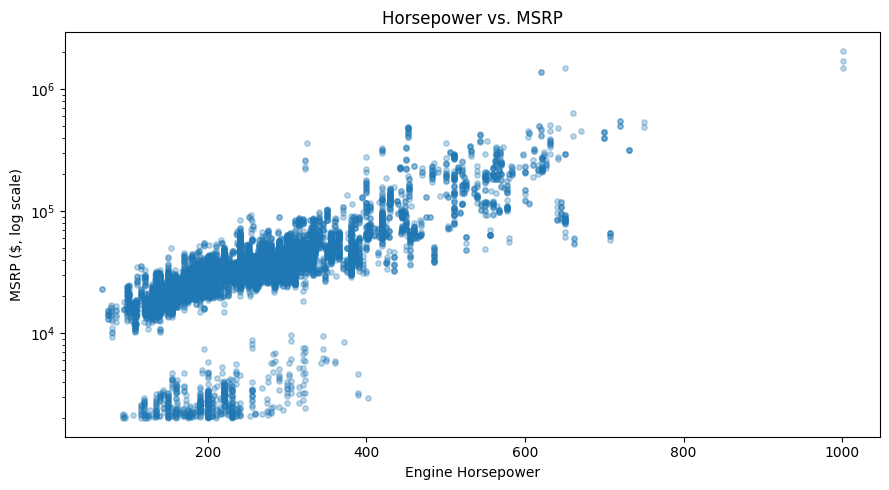

In [21]:
# S1

# Select valid horsepower and price values
hp_data = clean[
    ["engine_hp", "msrp"]
].dropna()

hp_data = hp_data[
    (hp_data["engine_hp"] > 0)
    & (hp_data["msrp"] > 0)
].copy()

# Calculate log price
hp_data["log_msrp"] = np.log10(hp_data["msrp"])

# a) Three correlations
pearson = hp_data["engine_hp"].corr(
    hp_data["msrp"],
    method="pearson"
)

pearson_log = hp_data["engine_hp"].corr(
    hp_data["log_msrp"],
    method="pearson"
)

spearman = hp_data["engine_hp"].corr(
    hp_data["msrp"],
    method="spearman"
)

print("Pearson correlation:", round(pearson, 3))
print("Pearson with log MSRP:", round(pearson_log, 3))
print("Spearman correlation:", round(spearman, 3))

# b) Scatter plot with log price axis
plt.figure(figsize=(9, 5))

plt.scatter(
    hp_data["engine_hp"],
    hp_data["msrp"],
    alpha=0.3,
    s=15
)

plt.yscale("log")
plt.title("Horsepower vs. MSRP")
plt.xlabel("Engine Horsepower")
plt.ylabel("MSRP ($, log scale)")

plt.tight_layout()
plt.show()


### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [22]:
# S2
# Select 2015–2017 cars with automatic or manual
s2 = clean[
    clean["year"].between(2015, 2017)
    & clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"])
].copy()

# Remove missing vehicle sizes
s2 = s2.dropna(subset=["vehicle_size"])

# Build crosstab
table = pd.crosstab(
    s2["vehicle_size"],
    s2["transmission_type"]
)

print("Vehicle size vs. transmission:")
display(table)

# Run chi-square test
chi2, p, dof, expected = stats.chi2_contingency(table)

print("Chi-square statistic:", round(chi2, 3))
print("p-value:", p)
print("Degrees of freedom:", dof)

print("\nMinimum expected cell count:", expected.min())

# Interpret result
if p < 0.05:
    print("Vehicle size and transmission type are associated.")
else:
    print("Insufficient evidence of an association.")


Vehicle size vs. transmission:


transmission_type,AUTOMATIC,MANUAL
vehicle_size,,
Compact,1119,589
Large,1473,26
Midsize,1919,198


Chi-square statistic: 756.929
p-value: 4.3146983717466523e-165
Degrees of freedom: 2

Minimum expected cell count: 228.90439519158528
Vehicle size and transmission type are associated.
